# Proyecto Integrador Grupo 3 · Informe Técnico y Presentación de Resultados
**Maestría en Inteligencia Artificial y Data Science para la Transformación de Negocios · UMSA – Postgrado en Informática**\
**Módulo:** Preparación, Recopilación y Análisis Exploratorio de Datos\
**Docente:** M.Sc. Marcelo Pinto Macedo\
**Equipo:** Grupo 3\
**Integrantes:** María Huampo, Limbert Nelson Escobar Mamani, Cristian Kelvin Espinoza Ortega, Jaime Gabriel Soto Gonzales\
**Caso:** Análisis de Ingreso Laboral y Gastos de los Hogares en Bolivia (Encuesta de Hogares EH2025 · INE)

---

### Marco Metodológico Integrado
El presente informe desarrolla de forma directa y exhaustiva la consigna analítica del proyecto integrador, articulando las cuatro sesiones formativas sobre los microdatos reales de la **Encuesta de Hogares 2025 (EH2025)** del Instituto Nacional de Estadística (INE) de Bolivia:

| Sección | Marco Teórico | Consigna y Desarrollo Analítico |
|---|---|---|
| **S1** | Sesión 1 · Introducción al análisis de datos | Taxonomía de escalas de medición (Stevens, 1946), tipificación de variables cualitativas, tratamiento de fechas (`datetime64`) y diagnóstico de sesgos de distribución. (Maria) |
| **S2** | Sesión 2 · Recopilación de datos | Modelado del tamaño muestral probabilístico (Cochran, 1977), simulación de representatividad territorial y justificación del muestreo estratificado multietápico con factores de expansión. (Jaime) |
| **S3** | Sesión 3 · Fuentes y extracción | Arquitectura relacional multinivel (Codd, 1970), pipeline de agregación y resolución cuantitativa de la pregunta de negocio (brecha urbana-rural, Ley de Engel y tasas de déficit). (Cristian) |
| **Cierre** | CRISP-DM, fase 2 | Ficha técnica e informe estandarizado de recolección y calidad inicial de datos (Chapman et al., 2000). (Limbert) |

### La Pregunta Central de Negocio
> **¿En qué medida la brecha de ingreso laboral entre el área urbana y rural condiciona la estructura del gasto (alimentos vs. no alimentos) en los nueve departamentos de Bolivia, y cuáles departamentos registran mayor vulnerabilidad presupuestaria?**

### Estructura de Ejecución
- El cuaderno presenta un flujo continuo de análisis formal orientado a la toma de decisiones, combinando código reproducible en Python, tablas descriptivas consolidadas y visualizaciones gráficas integradas.
- Todas las celdas se ejecutan secuencialmente sobre el entorno virtual local (`.venv`).

## Paso 0 · El conjunto de datos y cómo lo obtenemos
**Encuesta de Hogares (EH2025) · Instituto Nacional de Estadística (INE Bolivia).**  
La Encuesta de Hogares es la principal fuente estadística oficial para la medición de la pobreza, el empleo, los ingresos y las condiciones de vida de la población boliviana. La muestra es probabilística, multietápica y estratificada a nivel nacional, departamental y por área (urbana / rural).

- **Fuente oficial:** Instituto Nacional de Estadística (INE Bolivia).
- **Formato:** Archivos CSV extraídos de las bases oficiales en SPSS (`.sav`) mediante `convertir_sav.py`.
- **Clave relacional común:** La columna `folio` identifica unívocamente a cada hogar encuestado en todo el país.

Para este estudio integramos cuatro tablas fundamentales:
1. `EH2025_Vivienda_1.csv`: Características de la vivienda, tamaño del hogar y diseño muestral (12 726 hogares).
2. `EH2025_Persona.csv`: Demografía, fechas de nacimiento, condición de actividad e ingresos laborales individuales (39 485 personas).
3. `EH2025_Gastos_No_Alimentarios.csv`: Gastos del hogar en transporte, educación, servicios, limpieza, etc. (12 726 hogares).
4. `EH2025_Gastos_Alimentarios.csv`: Detalle de compras en efectivo y autoconsumo en 75 productos alimenticios (954 450 registros).

In [2]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configuracion de visualizacion en pandas
pd.set_option('display.max_columns', 25)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

# Carga de las 4 tablas principales
vivienda = pd.read_csv('EH2025_Vivienda_1.csv', low_memory=False)
persona = pd.read_csv('EH2025_Persona.csv', low_memory=False)
gastos_no_alim = pd.read_csv('EH2025_Gastos_No_Alimentarios.csv', low_memory=False)
gastos_alim = pd.read_csv('EH2025_Gastos_Alimentarios.csv', usecols=['folio', 'depto', 'area', 'producto', 's08a_04', 's08a_07'])

print(f"vivienda:         {vivienda.shape[0]:,} filas × {vivienda.shape[1]} columnas")
print(f"persona:          {persona.shape[0]:,} filas × {persona.shape[1]} columnas")
print(f"gastos_no_alim:   {gastos_no_alim.shape[0]:,} filas × {gastos_no_alim.shape[1]} columnas")
print(f"gastos_alim:      {gastos_alim.shape[0]:,} filas × {gastos_alim.shape[1]} columnas")

vivienda:         12,726 filas × 64 columnas
persona:          39,485 filas × 276 columnas
gastos_no_alim:   12,726 filas × 66 columnas
gastos_alim:      954,450 filas × 6 columnas


**Resultado esperado:**  
`vivienda` (12 726 × 64) · `persona` (39 485 × 276) · `gastos_no_alim` (12 726 × 66) · `gastos_alim` (954 450 × 6).  
Todas las tablas están disponibles localmente y comparten la clave foránea `folio`.

---
# S1 · De la Sesión 1: tipos de datos y escalas de medición
**Recordemos:** Stevens (1946) propuso cuatro escalas — **nominal, ordinal, intervalo y razón** — y la escala determina qué operaciones y cálculos matemáticos son válidos sobre cada variable.

### S1.1 · Primera mirada a los datos
Inspeccionemos la estructura inicial de las personas y de la vivienda.

In [3]:
persona[['folio', 'nro', 's01a_02', 's01a_03', 's01a_04a', 's01a_04b', 's01a_04c', 's01a_05', 'condact', 'ylab']].head(5)

,folio,nro,s01a_02,s01a_03,s01a_04a,s01a_04b,s01a_04c,s01a_05,condact,ylab
0,111-000005-A-0011,1.00,1.00,43.00,20.00,1.00,"1,982.00",1.00,1.00,"2,165.00"
1,111-000005-A-0011,2.00,2.00,39.00,12.00,3.00,"1,986.00",2.00,1.00,"1,500.00"
2,111-000005-A-0011,3.00,2.00,4.00,15.00,7.00,"2,021.00",3.00,NaN,NaN
3,111-000005-A-0021,1.00,1.00,43.00,26.00,6.00,"1,982.00",1.00,1.00,"3,000.00"
4,111-000005-A-0021,2.00,2.00,41.00,26.00,7.00,"1,984.00",2.00,1.00,"1,500.00"


In [4]:
vivienda[['folio', 'depto', 'area', 'totper', 'factor']].info()

<class 'pandas.DataFrame'>
RangeIndex: 12726 entries, 0 to 12725
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   folio   12726 non-null  str    
 1   depto   12726 non-null  float64
 2   area    12726 non-null  float64
 3   totper  12726 non-null  float64
 4   factor  12726 non-null  float64
dtypes: float64(4), str(1)
memory usage: 497.2 KB


**Qué observar:**  
- `folio` es un código alfanumérico compuesto (por ejemplo `111-000005-A-0011`). Es un identificador que debe tratarse como **texto**.
- `depto` y `area` aparecen como números reales (`float64`), pero son códigos cualitativos (códigos nominales). Promediar `depto` carece de sentido conceptual.
- `s01a_04a`, `s01a_04b` y `s01a_04c` representan el día, mes y año de nacimiento. Requieren tratamiento especial para consolidarse como una variable de fecha (`datetime64`).
- `ylab` representa el ingreso laboral individual en Bolivianos mensuales (escala de razón). Observamos valores `NaN` en miembros que no son perceptores de ingresos laborales (niños, dependientes, inactivos).

### S1.2 · Variable de fecha y escala de intervalo: construcción de `fecha_nacimiento`
Uno de los requisitos metodológicos del proyecto integrador (Sesión 4, diapositiva 14) es contar con **al menos una variable de fecha** tratada como tipo temporal nativo (`datetime64`).

En la encuesta, el nacimiento de cada persona se registra en tres campos numéricos separados:
* `s01a_04a`: Día de nacimiento (1 a 31).
* `s01a_04b`: Mes de nacimiento (1 a 12).
* `s01a_04c`: Año de nacimiento (ej. 1985, 2002).

Consolidamos estos campos en formato ISO (`AAAA-MM-DD`) y los convertimos a `datetime64` con `pd.to_datetime(...)`.

**Fundamento estadístico (Stevens, 1946):**  
Las fechas pertenecen a la **escala de intervalo** porque el punto cero es arbitrario (calendario gregoriano) y no tiene sentido afirmar que un año es «el doble» de otro. Sin embargo, la **diferencia o distancia** entre dos fechas tiene pleno sentido matemático: restando la fecha de levantamiento de la encuesta de la fecha de nacimiento podemos verificar con precisión la edad exacta de cada individuo.

In [5]:
# Construccion de la fecha en formato ISO 'AAAA-MM-DD'
cadena_fechas = (
    persona['s01a_04c'].astype(str).str.split('.').str[0] + '-' +
    persona['s01a_04b'].astype(str).str.split('.').str[0].str.zfill(2) + '-' +
    persona['s01a_04a'].astype(str).str.split('.').str[0].str.zfill(2)
)

# Conversion a tipo nativo datetime64
fecha_nac = pd.to_datetime(cadena_fechas, errors='coerce')

# Operacion de escala de intervalo: calculo de la edad exacta a la fecha de la encuesta
fecha_referencia_encuesta = pd.to_datetime('2025-11-01')
dias_calculados = (fecha_referencia_encuesta - fecha_nac).dt.days
edad_anios = (dias_calculados / 365.25).round(1)

# Asignacion conjunta eficiente (evita fragmentacion de memoria en DataFrames anchos)
persona = persona.copy().assign(
    fecha_nacimiento=fecha_nac,
    edad_calculada_dias=dias_calculados,
    edad_exacta_anios=edad_anios
)

print("Tipo de dato de fecha_nacimiento:", persona['fecha_nacimiento'].dtype)
print(f"Registros de fecha válidos: {persona['fecha_nacimiento'].notna().sum():,} de {len(persona):,}")
print()
persona[['s01a_04a', 's01a_04b', 's01a_04c', 'fecha_nacimiento', 's01a_03', 'edad_exacta_anios']].head(5)

Tipo de dato de fecha_nacimiento: datetime64[us]
Registros de fecha válidos: 39,485 de 39,485



,s01a_04a,s01a_04b,s01a_04c,fecha_nacimiento,s01a_03,edad_exacta_anios
0,20.00,1.00,"1,982.00",1982-01-20,43.00,43.80
1,12.00,3.00,"1,986.00",1986-03-12,39.00,39.60
2,15.00,7.00,"2,021.00",2021-07-15,4.00,4.30
3,26.00,6.00,"1,982.00",1982-06-26,43.00,43.40
4,26.00,7.00,"1,984.00",1984-07-26,41.00,41.30


**Resultado esperado:**  
La columna `fecha_nacimiento` queda almacenada como `datetime64[ns]`. La persona más longeva nació en **1927** y la más joven a finales de **2025**. La edad calculada mediante la diferencia temporal coincide con la edad declarada (`s01a_03`).

### S1.3 · Un número que no es un número: mapeo semántico de categorías
En las encuestas del INE, variables nominales como departamento (`depto`) y área geográfica (`area`) vienen codificadas numéricamente según el estándar del diccionario de datos:
- `depto`: 1 = Chuquisaca, 2 = La Paz, 3 = Cochabamba, 4 = Oruro, 5 = Potosí, 6 = Tarija, 7 = Santa Cruz, 8 = Beni, 9 = Pando.
- `area`: 1 = Urbana, 2 = Rural.

Asignamos etiquetas semánticas explícitas para evitar errores analíticos:

In [6]:
# Mapeo oficial segun Diccionario_datos.xml
depto_map = {
    1: 'Chuquisaca', 2: 'La Paz', 3: 'Cochabamba', 4: 'Oruro',
    5: 'Potosí', 6: 'Tarija', 7: 'Santa Cruz', 8: 'Beni', 9: 'Pando'
}
area_map = {1: 'Urbana', 2: 'Rural'}

# Aplicamos a vivienda de forma consolidada
vivienda = vivienda.copy().assign(
    departamento=vivienda['depto'].map(depto_map).astype('category'),
    nombre_area=vivienda['area'].map(area_map).astype('category')
)
vivienda['folio'] = vivienda['folio'].astype(str).str.strip()

vivienda[['folio', 'depto', 'departamento', 'area', 'nombre_area', 'totper']].head(4)

,folio,depto,departamento,area,nombre_area,totper
0,114-002315-A-0061,1.00,Chuquisaca,1.00,Urbana,6.00
1,114-002315-A-0091,1.00,Chuquisaca,1.00,Urbana,4.00
2,114-002315-A-0081,1.00,Chuquisaca,1.00,Urbana,1.00
3,114-002315-A-0071,1.00,Chuquisaca,1.00,Urbana,2.00


### S1.4 · Escala de cada variable (Taxonomía de Stevens, 1946)

| Variable | Tabla | Escala | Tipo en Python | Cálculos válidos |
|---|---|---|---|---|
| `folio` (id de hogar) | Todas | **Nominal** | `str` | Frecuencias, enlace relacional |
| `departamento` (`depto`) | Todas | **Nominal** | `category` | Frecuencias, moda, tablas de contingencia |
| `nombre_area` (`area`) | Todas | **Nominal** | `category` | Proporciones, tabulaciones cruzadas |
| `s01a_05` (parentesco con jefe) | `persona` | **Nominal** | `int` / `category` | Frecuencias, filtrado del jefe de hogar |
| `aestudio` (años de estudio) | `persona` | **Razón** / Discreta | `float64` | Mediana, percentiles, media |
| `fecha_nacimiento` | `persona` | **Intervalo** | `datetime64[ns]` | Diferencias entre fechas, cálculo de edad, orden temporal |
| `ylab` (ingreso laboral individual) | `persona` | **Razón** | `float64` | Media, mediana, dispersión, ratios relativos |
| `s08a_04` (compra alimentos) | `gastos_alim` | **Razón** | `float64` | Sumas, razones de gasto, porcentajes |
| `totper` (miembros en hogar) | `vivienda` | **Razón** / Discreta | `int64` | Media, total, per cápita |

In [7]:
print("Distribución de hogares por área:")
print(vivienda['nombre_area'].value_counts())
print()
print("Distribución de hogares por departamento:")
print(vivienda['departamento'].value_counts().sort_index())

Distribución de hogares por área:
nombre_area
Urbana    9611
Rural     3115
Name: count, dtype: int64

Distribución de hogares por departamento:
departamento
Beni           686
Chuquisaca     911
Cochabamba    2198
La Paz        3108
Oruro          986
Pando          578
Potosí        1037
Santa Cruz    2289
Tarija         933
Name: count, dtype: int64


**Resultado esperado:**  
Área Urbana: 9 611 hogares (75.5 %) · Área Rural: 3 115 hogares (24.5 %).  
La Paz (3 108), Santa Cruz (2 289) y Cochabamba (2 198) conforman el eje central con mayor volumen muestral.

### S1.5 · Tratamiento de valores ausentes y ceros en ingresos (`ylab`)
En variables de razón socioeconómicas como el ingreso laboral:
1. Las personas que **no trabajan** (estudiantes, niños, jubilados) tienen `ylab` como `NaN` o 0.
2. La distribución de los perceptores ocupados suele tener un **fuerte sesgo positivo (hacia la derecha)**: unos pocos perceptores con salarios altos elevan la media aritmética por encima del salario típico (la **mediana**).

In [8]:
# Analisis sobre perceptores con ingreso laboral positivo
ocupados_con_ingreso = persona[persona['ylab'] > 0]['ylab']
print(f"Total perceptores con ingreso laboral registrado: {len(ocupados_con_ingreso):,}")
print(ocupados_con_ingreso.describe().round(2))

Total perceptores con ingreso laboral registrado: 17,038
count    17,038.00
mean      3,623.94
std       4,333.65
min           4.17
25%       1,700.00
50%       2,979.17
75%       4,475.00
max     369,897.00
Name: ylab, dtype: float64


### S1.6 · Caracterización demográfica: perfil por sexo de las jefaturas de hogar
Identificamos a los **jefes de hogar** en la base de personas (`s01a_05 == 1`) y evaluamos la distribución según sexo (`s01a_02`), permitiendo medir la presencia de jefaturas femeninas en los hogares de Bolivia:

In [9]:
# Filtrar jefes de hogar
jefes_hogar = persona[persona['s01a_05'] == 1]

# Mapear sexo (1: Hombre, 2: Mujer)
sexo_map = {1: 'Hombre', 2: 'Mujer'}
conteo_sexo_jefes = jefes_hogar['s01a_02'].map(sexo_map).value_counts()
print("Distribución por sexo de las jefaturas de hogar:")
print(conteo_sexo_jefes)
print(f"\nPorcentaje de mujeres jefas de hogar: {conteo_sexo_jefes['Mujer'] / len(jefes_hogar) * 100:.2f} %")

Distribución por sexo de las jefaturas de hogar:
s01a_02
Hombre    8466
Mujer     4260
Name: count, dtype: int64

Porcentaje de mujeres jefas de hogar: 33.47 %


### S1.7 · Diagnóstico de brecha salarial por sexo en la población ocupada
Comparamos la **media** y la **mediana** del ingreso laboral mensual (`ylab`) entre hombres y mujeres ocupados que perciben remuneración económica. La marcada distancia entre media y mediana ratifica la asimetría positiva en ambos grupos y pone en evidencia la magnitud de la brecha salarial por género:

In [10]:
ocupados = persona[persona['ylab'] > 0].copy()
ocupados['sexo'] = ocupados['s01a_02'].map(sexo_map)

resumen_brecha = ocupados.groupby('sexo')['ylab'].agg(['count', 'mean', 'median', 'std']).round(2)
resumen_brecha.columns = ['Perceptores', 'Media (Bs)', 'Mediana (Bs)', 'Desv. Est.']
print("Comparativo salarial por sexo en trabajadores ocupados:")
print(resumen_brecha)

Comparativo salarial por sexo en trabajadores ocupados:
        Perceptores  Media (Bs)  Mediana (Bs)  Desv. Est.
sexo                                                     
Hombre        10082    4,009.07      3,247.50    5,092.00
Mujer          6956    3,065.73      2,500.00    2,809.96


---
# S2 · De la Sesión 2: tamaño de muestra y muestreo
**Recordando:** La fórmula de **Cochran (1977)** determina el tamaño óptimo de muestra bajo muestreo aleatorio simple con corrección por población finita ($N$):

$$n_0 = \frac{Z^2 \cdot p \cdot (1 - p)}{e^2}, \quad n = \frac{n_0}{1 + \frac{n_0 - 1}{N}}$$

Donde para una confianza del 95 %, $Z = 1.96$, y bajo máxima variabilidad, $p = 0.5$.

### S2.1 · Tamaño de muestra para la población de hogares
Si considerásemos el total de hogares de la muestra ($N = 12,726$) como nuestra población objetivo para un estudio rápido de calidad:

In [11]:
def tamano_muestra_cochran(N, e=0.05, z=1.96, p=0.5):
    n0 = (z**2 * p * (1 - p)) / (e**2)
    n = n0 / (1 + (n0 - 1) / N)
    return math.ceil(n)

N_hogares = len(vivienda)
n_5pct = tamano_muestra_cochran(N_hogares, e=0.05)
n_3pct = tamano_muestra_cochran(N_hogares, e=0.03)

print(f"Población finita N = {N_hogares:,} hogares")
print(f"Muestra requerida al 5 % de error (95 % conf.): {n_5pct} hogares")
print(f"Muestra requerida al 3 % de error (95 % conf.): {n_3pct} hogares")

Población finita N = 12,726 hogares
Muestra requerida al 5 % de error (95 % conf.): 373 hogares
Muestra requerida al 3 % de error (95 % conf.): 985 hogares


### S2.2 · Muestreo Aleatorio Simple frente a Estratificado
¿Por qué el INE encuesta a 12 726 hogares en lugar de solo 373?
Porque un **Muestreo Aleatorio Simple (MAS)** de 373 hogares a nivel nacional dejaría a los estratos pequeños (departamentos de menor población como Pando o Beni, o el área rural de regiones montañosas) con muy pocos casos para inferencias locales confiables.

Comprobemos qué pasaría con una muestra aleatoria de $n = 373$ hogares frente a la distribución estratificada real:

In [12]:
# Muestra aleatoria simple simulada (n = 373)
np.random.seed(42)
muestra_aleatoria = vivienda.sample(n=n_5pct, random_state=42)

# Comparacion de representatividad por departamento
prop_poblacion = vivienda['departamento'].value_counts(normalize=True) * 100
prop_aleatoria = muestra_aleatoria['departamento'].value_counts(normalize=True) * 100

comparativa_muestreo = pd.DataFrame({
    'Población EH (%)': prop_poblacion,
    'Muestra MAS n=373 (%)': prop_aleatoria,
    'Casos MAS': muestra_aleatoria['departamento'].value_counts()
}).round(2)

print("Comparación de distribución departamental:")
print(comparativa_muestreo)

Comparación de distribución departamental:
              Población EH (%)  Muestra MAS n=373 (%)  Casos MAS
departamento                                                    
Beni                      5.39                   5.09         19
Chuquisaca                7.16                   5.90         22
Cochabamba               17.27                  16.35         61
La Paz                   24.42                  24.13         90
Oruro                     7.75                  10.99         41
Pando                     4.54                   4.56         17
Potosí                    8.15                   7.51         28
Santa Cruz               17.99                  16.35         61
Tarija                    7.33                   9.12         34


### S2.3 · El rol del Factor de Expansión (`factor`)
Para corregir la sobre-representación intencional de departamentos pequeños y áreas rurales (diseño muestral complejo), el INE asigna a cada hogar un **factor de expansión**. Este factor indica a cuántos hogares de la población boliviana real representa ese registro encuestado.

In [13]:
vivienda.groupby(['departamento', 'nombre_area'], observed=False)['factor'].agg(['count', 'min', 'median', 'max']).round(1)

count    min  median      max
departamento nombre_area                               
Beni         Rural          166  68.20  231.90   456.20
             Urbana         520  66.10  181.50 1,121.60
Chuquisaca   Rural          414  53.40  192.80   783.20
             Urbana         497  60.60  209.40   548.50
Cochabamba   Rural          397 114.90  407.50 1,822.90
             Urbana        1801  62.40  254.00   878.50
La Paz       Rural          427 188.00  682.70 2,952.80
             Urbana        2681  52.70  229.00   656.70
Oruro        Rural          395  63.70  147.70   919.70
             Urbana         591  45.30  188.90   485.30
Pando        Rural          237  16.90   53.80   369.70
             Urbana         341  25.10   64.30   272.60
Potosí       Rural          572  84.00  249.80 1,167.20
             Urbana         465  44.40  232.90   583.60
Santa Cruz   Rural          261 236.90  504.00 1,575.60
             Urbana        2028  45.20  386.30 2,025.90
Tarija       Rural          246 111.80  217.70   373.40
             Urbana         687  55.20  161.60   893.90

### S2.4 · Escenarios de precisión muestral: dimensionamiento al 2 % de margen de error
Para estudios de fiscalización, auditoría o focalización de subsidios que exijan una tolerancia al error más reducida ($e = 0.02$) con un 95 % de nivel de confianza, evaluamos el tamaño de muestra teórico sobre la población de $N = 12,726$ hogares:

In [14]:
n_2pct = tamano_muestra_cochran(N_hogares, e=0.02)
print(f"Muestra requerida bajo criterio estricto (error del 2 % y confianza del 95 %): {n_2pct:,} hogares")

Muestra requerida bajo criterio estricto (error del 2 % y confianza del 95 %): 2,021 hogares


---
# S3 · De la Sesión 3: fuentes e integración de tablas (Codd, 1970)
**Recordemos:** Edgar Codd (1970) sentó las bases del modelo relacional: entidades independientes en tablas estructuradas vinculadas por **claves primarias y foráneas**.

### S3.1 · El modelo relacional de la EH2025
```
EH2025_Vivienda_1 ──(folio 1:1)── EH2025_Gastos_No_Alimentarios
        │                                  │
    (folio 1:N)                       (folio 1:1)
        │                                  │
EH2025_Persona                  Gasto No Alim Mensual
 (Agregación)
        │
   ylab_hogar
   ylab_jefe
   fecha_nac_jefe
        │
        └─────────────────(folio 1:N)── EH2025_Gastos_Alimentarios
                                                │
                                       (Agregación por folio)
                                                │
                                       gasto_alim_compra
                                       gasto_alim_total
```

### S3.2 · Pipeline de agregación relacional a nivel de Hogar
Dado que `persona` tiene nivel individual (39 485 registros) y `gastos_alim` nivel producto (954 450 registros), debemos agregarlos al nivel unificado de **hogar** (`folio`, 12 726 registros):

1. **Ingreso Laboral y Características del Jefe:**
   - $\text{ylab\_hogar}$: Suma de los ingresos laborales de todos los perceptores del hogar.
   - $\text{ylab\_jefe}$: Ingreso laboral específico de la jefa o jefe de hogar (`s01a_05 == 1`).
   - $\text{fecha\_nacimiento\_jefe}$: Fecha de nacimiento de la jefa o jefe de hogar (`datetime64`).
2. **Gastos Alimentarios:**
   - $\text{gasto\_alim\_compra}$: Suma de compras monetarias en efectivo (`s08a_04`).
   - $\text{gasto\_alim\_total}$: Compra monetaria + autoconsumo imputado (`s08a_04 + s08a_07`).
3. **Gastos No Alimentarios:**
   - Suma horizontal de los 28 rubros mensuales de consumo (`s08b_10_01` a `s08b_10_28`).

In [15]:
# 1. Agregacion Persona -> Hogar
hogar_per = persona.groupby('folio').agg(
    ylab_hogar=('ylab', 'sum'),
    n_perceptores=('ylab', lambda s: (s > 0).sum())
).reset_index()

# Extraer ingresos y fecha del jefe de hogar (s01a_05 == 1)
jefes = persona[persona['s01a_05'] == 1][['folio', 'ylab', 's01a_02', 's01a_03', 'fecha_nacimiento', 'aestudio']].copy()
jefes.columns = ['folio', 'ylab_jefe', 'sexo_jefe', 'edad_jefe', 'fecha_nacimiento_jefe', 'aestudio_jefe']
jefes['ylab_jefe'] = jefes['ylab_jefe'].fillna(0)

# Unir agregados de personas
per_consolidado = hogar_per.merge(jefes, on='folio', how='left')

# 2. Agregacion Gastos Alimentarios -> Hogar
alim_hogar = gastos_alim.groupby('folio').agg(
    gasto_alim_compra=('s08a_04', 'sum'),
    gasto_alim_autoconsumo=('s08a_07', 'sum')
).reset_index()
alim_hogar['gasto_alim_total'] = alim_hogar['gasto_alim_compra'] + alim_hogar['gasto_alim_autoconsumo']

# 3. Gastos No Alimentarios (Suma de rubros mensuales s08b_10_*)
cols_no_alim = [c for c in gastos_no_alim.columns if c.startswith('s08b_10_')]
gastos_no_alim = gastos_no_alim.copy()
gastos_no_alim['gasto_no_alim_mes'] = gastos_no_alim[cols_no_alim].fillna(0).sum(axis=1)
no_alim_hogar = gastos_no_alim[['folio', 'gasto_no_alim_mes']].copy()

# 4. Integracion final con tabla Vivienda
hogares = vivienda[['folio', 'depto', 'departamento', 'area', 'nombre_area', 'totper', 'factor']].merge(
    per_consolidado, on='folio', how='left'
).merge(
    alim_hogar, on='folio', how='left'
).merge(
    no_alim_hogar, on='folio', how='left'
)

# Imputar ceros en gastos si algun hogar no registro
for col in ['gasto_alim_compra', 'gasto_alim_autoconsumo', 'gasto_alim_total', 'gasto_no_alim_mes', 'ylab_hogar', 'ylab_jefe']:
    hogares[col] = hogares[col].fillna(0)

print(f"Tabla maestra de hogares consolidada: {hogares.shape[0]:,} filas × {hogares.shape[1]} columnas")
hogares[['folio', 'departamento', 'nombre_area', 'ylab_hogar', 'ylab_jefe', 'fecha_nacimiento_jefe', 'gasto_alim_compra', 'gasto_alim_total', 'gasto_no_alim_mes']].head(4)

Tabla maestra de hogares consolidada: 12,726 filas × 18 columnas


,folio,departamento,nombre_area,ylab_hogar,ylab_jefe,fecha_nacimiento_jefe,gasto_alim_compra,gasto_alim_total,gasto_no_alim_mes
0,114-002315-A-0061,Chuquisaca,Urbana,"15,866.67","4,700.00",1979-06-27,"1,237.00","1,237.00","2,080.00"
1,114-002315-A-0091,Chuquisaca,Urbana,"9,110.68","1,277.35",1962-04-08,807.00,881.00,"2,130.00"
2,114-002315-A-0081,Chuquisaca,Urbana,"1,221.06","1,221.06",1944-04-02,217.00,217.00,610.00
3,114-002315-A-0071,Chuquisaca,Urbana,0.00,0.00,1950-02-02,495.00,495.00,890.00


### S3.3 · La pregunta de negocio: Brecha laboral, Ley de Engel y Déficit presupuestario
Construimos los indicadores clave para responder la pregunta de negocio:

* **Gasto total monetario (en efectivo):** $\text{gasto\_alim\_compra} + \text{gasto\_no\_alim\_mes}$
* **Gasto total ampliado (incluye autoconsumo):** $\text{gasto\_alim\_total} + \text{gasto\_no\_alim\_mes}$
* **Propensión al gasto en alimentos (Ley de Engel):**
  $$\text{prop\_alim\_compra} = \frac{\text{gasto\_alim\_compra}}{\text{gasto\_total\_monetario}} \times 100$$
* **Déficit presupuestario frente a ingreso laboral:**
  $$\text{deficit\_hogar} = (\text{ylab\_hogar} < \text{gasto\_total\_monetario})$$
  $$\text{deficit\_jefe} = (\text{ylab\_jefe} < \text{gasto\_total\_monetario})$$

In [16]:
# Calculo de gastos totales e indicadores
hogares['gasto_total_monetario'] = hogares['gasto_alim_compra'] + hogares['gasto_no_alim_mes']
hogares['gasto_total_ampliado'] = hogares['gasto_alim_total'] + hogares['gasto_no_alim_mes']

hogares['prop_alim_compra'] = np.where(
    hogares['gasto_total_monetario'] > 0,
    (hogares['gasto_alim_compra'] / hogares['gasto_total_monetario']) * 100, 0
)

hogares['prop_alim_ampliada'] = np.where(
    hogares['gasto_total_ampliado'] > 0,
    (hogares['gasto_alim_total'] / hogares['gasto_total_ampliado']) * 100, 0
)

hogares['deficit_hogar'] = (hogares['ylab_hogar'] < hogares['gasto_total_monetario']).astype(int)
hogares['deficit_jefe'] = (hogares['ylab_jefe'] < hogares['gasto_total_monetario']).astype(int)

print("Indicadores derivados calculados exitosamente.")

Indicadores derivados calculados exitosamente.


#### 1. Brecha de Ingreso Laboral: Área Urbana frente a Rural
Comparamos el ingreso laboral generado por el total del hogar (`ylab_hogar`) y por la jefa o jefe de hogar (`ylab_jefe`):

In [17]:
resumen_ingresos = hogares.groupby('nombre_area', observed=False)[['ylab_hogar', 'ylab_jefe']].agg(['mean', 'median']).round(2)
print("Comparación de ingresos laborales (Bs/mes):")
print(resumen_ingresos)

Comparación de ingresos laborales (Bs/mes):
            ylab_hogar          ylab_jefe         
                  mean   median      mean   median
nombre_area                                       
Rural         3,073.31 1,948.50  2,250.23 1,300.00
Urbana        5,428.29 4,325.77  3,476.42 2,950.00


#### 2. Estructura del Gasto: Cumplimiento de la Ley de Engel
Evaluamos el porcentaje del gasto destinado a la alimentación bajo dos ópticas: solo compra monetaria y canasta ampliada con autoconsumo:

In [18]:
resumen_engel = hogares.groupby('nombre_area', observed=False)[['prop_alim_compra', 'prop_alim_ampliada']].mean().round(2)
resumen_engel.columns = ['% Alimentos (Compra Monetaria)', '% Alimentos (Con Autoconsumo)']
print("Propensión media al gasto alimentario (% del presupuesto):")
print(resumen_engel)

Propensión media al gasto alimentario (% del presupuesto):
             % Alimentos (Compra Monetaria)  % Alimentos (Con Autoconsumo)
nombre_area                                                               
Rural                                 63.25                          69.04
Urbana                                41.14                          41.69


#### 3. Vulnerabilidad y Tasa de Déficit por Departamento y Área
Presentamos la tabla resumen completa por departamento y área geográfica, identificando las regiones con mayor brecha y déficit:

In [19]:
resumen_departamental = hogares.groupby(['departamento', 'nombre_area'], observed=False).agg(
    mediana_ingreso_hogar=('ylab_hogar', 'median'),
    mediana_ingreso_jefe=('ylab_jefe', 'median'),
    gasto_monetario_medio=('gasto_total_monetario', 'mean'),
    prop_alimentos_media=('prop_alim_compra', 'mean'),
    tasa_deficit_hogar=('deficit_hogar', lambda x: round(x.mean() * 100, 1)),
    tasa_deficit_jefe=('deficit_jefe', lambda x: round(x.mean() * 100, 1)),
    n_hogares=('folio', 'count')
).reset_index()

print(resumen_departamental.to_string(index=False))

departamento nombre_area  mediana_ingreso_hogar  mediana_ingreso_jefe  gasto_monetario_medio  prop_alimentos_media  tasa_deficit_hogar  tasa_deficit_jefe  n_hogares
        Beni       Rural               3,000.00              2,301.85               1,084.38                 52.71               16.90              29.50        166
        Beni      Urbana               3,952.31              2,526.53               1,502.98                 40.75               13.50              31.20        520
  Chuquisaca       Rural               1,425.00                961.83               1,137.49                 67.54               32.90              44.70        414
  Chuquisaca      Urbana               4,063.33              2,598.00               1,942.37                 47.37               19.70              35.60        497
  Cochabamba       Rural               1,204.17              1,000.00               1,033.43                 59.57               36.00              42.80        397
  Cochabam

#### 4. Visualización: Tasa de Déficit Presupuestario por Departamento y Área

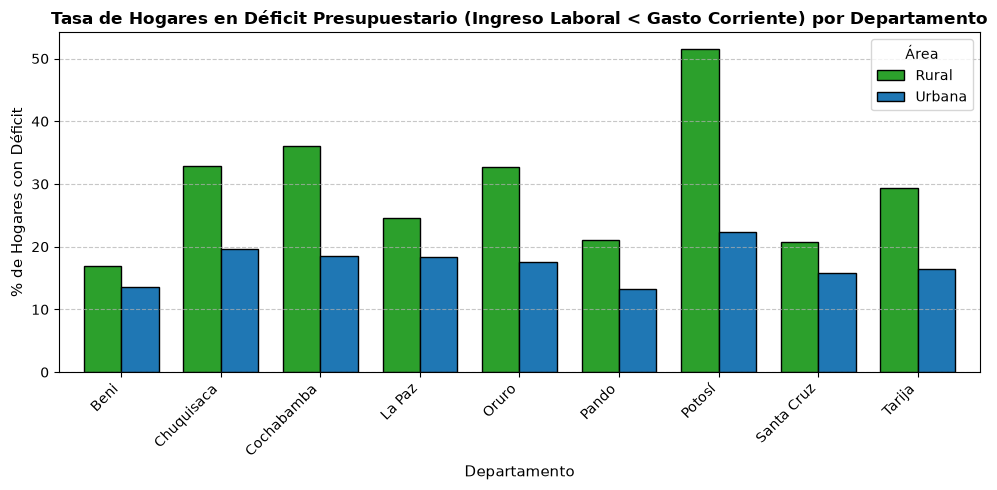

In [20]:
# Preparar datos para grafico de barras
tabla_pivot = resumen_departamental.pivot(index='departamento', columns='nombre_area', values='tasa_deficit_hogar')

fig, ax = plt.subplots(figsize=(10, 5))
tabla_pivot.plot(kind='bar', ax=ax, color=['#2ca02c', '#1f77b4'], edgecolor='black', width=0.75)

ax.set_title('Tasa de Hogares en Déficit Presupuestario (Ingreso Laboral < Gasto Corriente) por Departamento', fontsize=12, fontweight='bold')
ax.set_xlabel('Departamento', fontsize=11)
ax.set_ylabel('% de Hogares con Déficit', fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.legend(title='Área')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### S3.4 · Diagnóstico de solvencia presupuestaria: ratio de cobertura laboral
Calculamos el **ratio de cobertura del gasto** ($\text{ylab\_hogar} / \text{gasto\_total\_monetario}$) para los hogares de cada departamento en el área urbana frente a la rural. Valores superiores a 1.0 reflejan capacidad de ahorro o financiamiento laboral autónomo, mientras que ratios cercanos a 1.0 o inferiores denotan estrés de subsistencia:

In [21]:
hogares['ratio_cobertura'] = np.where(
    hogares['gasto_total_monetario'] > 0,
    hogares['ylab_hogar'] / hogares['gasto_total_monetario'], np.nan
)

ratio_cobertura_depto = hogares.groupby(['departamento', 'nombre_area'], observed=False)['ratio_cobertura'].median().unstack().round(2)
print("Mediana del ratio de cobertura (Ingreso Laboral del Hogar / Gasto Monetario Corriente):")
print(ratio_cobertura_depto)

Mediana del ratio de cobertura (Ingreso Laboral del Hogar / Gasto Monetario Corriente):
nombre_area   Rural  Urbana
departamento               
Beni           3.08    3.18
Chuquisaca     1.68    2.53
Cochabamba     1.76    2.55
La Paz         2.13    2.49
Oruro          1.86    2.58
Pando          2.44    2.74
Potosí         0.92    2.53
Santa Cruz     2.44    2.50
Tarija         1.98    2.69


### S3.5 · Factores de vulnerabilidad: dependencia de un perceptor único de ingresos
Identificamos qué proporción de familias en cada departamento y área geográfica dependen exclusivamente de los ingresos de un **único perceptor laboral** (`n_perceptores == 1`), configurando una condición de alta exposición ante eventualidades de desempleo o pérdida de ingresos:

In [22]:
hogares['un_solo_perceptor'] = (hogares['n_perceptores'] == 1).astype(int)
perceptor_unico = hogares.groupby(['departamento', 'nombre_area'], observed=False)['un_solo_perceptor'].mean().mul(100).unstack().round(1)
print("Porcentaje de hogares con un único perceptor de ingreso laboral (%):")
print(perceptor_unico)

Porcentaje de hogares con un único perceptor de ingreso laboral (%):
nombre_area   Rural  Urbana
departamento               
Beni          66.90   56.70
Chuquisaca    68.60   49.10
Cochabamba    75.30   50.20
La Paz        71.40   49.80
Oruro         71.90   55.80
Pando         67.90   52.80
Potosí        71.50   57.60
Santa Cruz    69.00   51.00
Tarija        63.80   53.60


---
# Cierre · Informe de recolección inicial (CRISP-DM, fase 2)
Siguiendo las directrices del modelo estándar de la industria **CRISP-DM** (Chapman et al., 2000), se documenta la fase de recolección, calidad y comprensión inicial de los datos para el caso del Grupo 3:

| Elemento | Proyecto Grupo 3 (EH2025 · Bolivia) |
|---|---|
| **Fuente** | Instituto Nacional de Estadística (INE) de Bolivia · Encuesta de Hogares 2025 |
| **Tipo de fuente** | Datos secundarios oficiales · encuesta por muestreo probabilístico y multietápico |
| **Formato y acceso** | Archivos CSV locales procesados con codificación UTF-8 (`convertir_sav.py`) |
| **Tablas integradas** | `vivienda` (12 726) · `persona` (39 485) · `gastos_no_alim` (12 726) · `gastos_alim` (954 450) |
| **Variables temporales tratadas** | `fecha_nacimiento` consolidada a partir de día (`s01a_04a`), mes (`s01a_04b`) y año (`s01a_04c`) en formato ISO (`AAAA-MM-DD`) tipo `datetime64[ns]`, operada bajo escala de intervalo. |
| **Población y periodo** | Hogares particulares y sus miembros residentes habituales en Bolivia (Gestión 2025) |
| **Problemas encontrados y tratados** | Disparidad de granularidades (persona vs. producto vs. hogar); variables cualitativas leídas como números continuos (`depto`, `area`); valores nulos en ingresos en personas no activas; asimetría positiva en salarios. |
| **Principales hallazgos** | 1. **Brecha urbana-rural:** La mediana del ingreso laboral del hogar urbano (Bs 4 325,77) más que duplica al rural (Bs 1 948,50).<br>2. **Ley de Engel:** Los hogares rurales destinan el 63,2 % de su gasto monetario a alimentos (69,0 % con autoconsumo), frente al 41,1 % en ciudades.<br>3. **Vulnerabilidad regional:** Potosí rural registra el mayor déficit laboral (51,6 % de los hogares no cubren su canasta corriente con ingreso laboral), mientras que los departamentos del eje y Pando muestran mayor capacidad de cobertura. |

---
**Referencias:**  
- Chapman, P., Clinton, J., Kerber, R., Khabaza, T., Reinartz, T., Shearer, C., & Wirth, R. (2000). *CRISP-DM 1.0: Step-by-step data mining guide*. SPSS.  
- Cochran, W. G. (1977). *Sampling techniques* (3.ª ed.). John Wiley & Sons.  
- Codd, E. F. (1970). A relational model of data for large shared data banks. *Communications of the ACM*, 13(6), 377–387.  
- Instituto Nacional de Estadística - INE (2025). *Encuesta de Hogares 2025: Ficha técnica y diccionario de variables*. La Paz, Bolivia.  
- Stevens, S. S. (1946). On the theory of scales of measurement. *Science*, 103(2684), 677–680.